In [29]:
## Script for analysis of neuroimaging data from Representations of Sentence Meaning in the Brain
# Run with python 3.10 fMRI env
# James Fodor 2024

# load libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import itertools
import pandas as pd
import os
import pickle

from random import choices
from scipy import stats
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from matplotlib.ticker import FormatStrFormatter
from joblib import Parallel, delayed

# load custom functions from library
import voxels_processing as vp

# set display options
np.set_printoptions(precision=3, threshold=6000, linewidth=220, suppress=True, floatmode='fixed')
sns.set()

In [30]:
import importlib
importlib.reload(vp)

<module 'voxels_processing' from 'd:\\Code\\Python\\2023_07_Sentence_Meaning_in_the_Brain\\voxels_processing.py'>

### Load stimuli data and similarities

In [31]:
## Load sentences and subjects data

# Load metadata for experimental subjects
subject_data_raw = np.loadtxt('Fodor2024-subject_data.txt', delimiter=';', dtype='str', encoding='utf-8', skiprows=1)
subject_data_dict = {sbj_data[0]:(sbj_data[1:]).astype('float') for sbj_data in subject_data_raw}
all_subjects = list(subject_data_dict.keys())
print('Loaded '+str(len(all_subjects))+' experimental subjects')

# set key parameters for loading data
dataset_name = 'Fodor2024-final108' # dataset name
repeats = [0,1,2,3] # stimulus repeats to include in analysis
num_sets = 6 # the number of sets of related sentences
timing = 'mid' # start, end, mid
corr_method = 'spearman'  # spearman or pearson correlation
similarity_type = 'cosine'  # options: 'cosine' or 'diemsim' or 'all'
controls_type = 1 # 1=sentence lengths only, 2=sentence lengths and minimum lengths, 3=visual cortex
accuracy_threshold = 0.73 # minimum accuracy on comprehension questions to include subjects (0.73 is default)
movement_threshold = 4.01 # maximum head movement (mean FD) to include subjects (4.01 is default)

# load sentences set
all_sentences = np.loadtxt(dataset_name+'_sentences.txt', delimiter=';', dtype='str', encoding='utf-8')
all_sentences_indices = np.arange(len(all_sentences))
sent_pairs_all = list(itertools.combinations(all_sentences_indices, 2))
sent_pair_ids_all = np.arange(len(sent_pairs_all))
num_stimuli = all_sentences_indices.shape[0]
sent_pair_ids_diag = vp.get_pairs_in_diag(all_sentences_indices, num_sets)
num_repeats = len(repeats)

# Load sentence pair types
sentpair_types_list = np.loadtxt('Fodor2024-final108_types-brief.txt', dtype=int)
sent_pair_ids_modsub = [idx for idx,type in enumerate(sentpair_types_list) if type==6]
sent_pair_ids_diffs = [idx for idx,type in enumerate(sentpair_types_list) if type==5]
sent_pair_ids_swaps = [idx for idx,type in enumerate(sentpair_types_list) if type==4]
sent_pair_ids_subs = [idx for idx,type in enumerate(sentpair_types_list) if type==3]
sent_pair_ids_mods = [idx for idx,type in enumerate(sentpair_types_list) if type==2]
sent_pair_ids_sames = [idx for idx,type in enumerate(sentpair_types_list) if type==1]
sent_pair_ids_key = [idx for idx,type in enumerate(sentpair_types_list) if type in [2,3,4,5]]

# print summary
print('Stimuli:',num_stimuli)
print('Timing:',timing)
print('Num repeats:',num_repeats)
print('All pairs:',len(sent_pair_ids_all))
print('Diag pairs:',len(sent_pair_ids_diag))
print('Control type:',controls_type)

Loaded 39 experimental subjects
Stimuli: 108
Timing: mid
Num repeats: 4
All pairs: 5778
Diag pairs: 918
Control type: 1


In [32]:
## Generate list of voxel sets for analysis
voxel_sets = []
for stability_level in ['0.04','0.07']:
    voxel_set_dict = vp.get_voxel_set_dict(stability_level)
    for voxel_set in voxel_set_dict:
        voxel_sets += voxel_set_dict[voxel_set]
        
voxel_sets = list(set(voxel_sets))
voxel_sets.sort()
default_voxel_set = 'LanROI-all-stable-0.07-norm'

In [33]:
## Set key parameters for computing similarities

# Specify voxel averaging and voxel subset options (for looping over later)
av_types = ['mean']
pair_subsets = ['all','diag']
other_parms = []
for av_type in av_types:
    for pair in pair_subsets:
        other_parms.append(av_type+'_'+pair)

# Collect subsets of sentences pairs for similarity analyses
similarity_subsets = {'all':sent_pair_ids_all, 'diag':sent_pair_ids_diag}
print('Voxel sets:',len(voxel_sets))

Voxel sets: 32


In [34]:
## Load model similarities and fmri similarities
 
# Load model similarities
model_sims_base = 'Data-models/similarities/'
model_sims_storage = vp.load_model_sims(model_sims_base, dataset_name, normalisation=True, sim_type=similarity_type)
model_sims_storage['transformers_norml_'+similarity_type] = np.random.rand(len(sent_pair_ids_all)) # blank entry for averaged transformers so they are in the dictionary
all_models = list(model_sims_storage.keys())
print('Loaded '+str(len(all_models))+' computational models')

# Load neuro similarities
fmri_sims_base = 'Data-fmri/similarities/'
neuro_sims_storage = dict(zip(all_subjects, [{type:{} for type in av_types} for x in all_subjects])) # blank empty dictionary for storage
for sbj_id in list(subject_data_dict.keys()):
    for av_type in av_types:
        for voxel_set in voxel_sets:
            neuro_sims_path = fmri_sims_base+timing+'_3s/'+'sub-'+sbj_id+'-sims/'
            with open(neuro_sims_path+'sub-'+sbj_id+'_similarities-'+av_type+'-'+voxel_set+'.txt', encoding='latin-1') as file:
                neuro_sims_storage[sbj_id][av_type][voxel_set] = np.array([float(line.rstrip('\n')) for line in file])
                              
# Specify which experimental subjects to include
included_subjects = [sbj_id for sbj_id in list(subject_data_dict.keys()) if subject_data_dict[sbj_id][0] >= accuracy_threshold and subject_data_dict[sbj_id][1] <= movement_threshold]
print('Including '+str(len(included_subjects))+' experimental subjects')

# Compute the average similarities over participants and store in dictionary
mean_subj_sims = {type:{} for type in av_types}
for av_type in av_types:
    for voxel_set in voxel_sets:
        voxelset_sims = [neuro_sims_storage[sbj_id][av_type][voxel_set] for sbj_id in included_subjects]
        mean_subj_sims[av_type][voxel_set] = np.mean(voxelset_sims, axis=0)
neuro_sims_storage['mean'] = mean_subj_sims
all_subjects = list(subject_data_dict.keys()) + ['mean'] # include mean subject data

# Load control variables
model_sims_storage['visual_sims'] = neuro_sims_storage['mean']['mean']['Glasser-primary_visual-stable-0.07-norm'] # visual similarities control
control_vars = vp.get_control_vars(controls_type, model_sims_storage)
print('Using '+str(controls_type)+' control variables')

Loaded 106 computational models
Including 30 experimental subjects
Using 1 control variables


### Compute all brain-model correlations

In [35]:
## Compute model-neuro correlations for all participants and all models

# Specity file locations for saving/loading correlations
neuro_coors_filename = "Data-analysis/"+dataset_name+"_"+timing+"_control-"+str(controls_type)+"_subs-"+str(len(included_subjects))+"_corrs_"+corr_method
neuro_pcoors_filename = "Data-analysis/"+dataset_name+"_"+timing+"_control-"+str(controls_type)+"_subs-"+str(len(included_subjects))+"_pcorrs_"+corr_method

# Load pre-computed correlations if present
try:
    with open(neuro_coors_filename+"_simpleav.pickle", "rb") as file:
        neuro_corrs_allsubjs = pickle.load(file)
    with open(neuro_pcoors_filename+"_simpleav.pickle", "rb") as file:
        neuro_pcorrs_allsubjs = pickle.load(file)
        
    # Determine which models are missing computed data
    presaved_models = list(neuro_corrs_allsubjs['05']['mean_all'][default_voxel_set].keys())
    missing_models = []
    for model in model_sims_storage.keys():
        if model not in presaved_models:
            missing_models.append(model)
    print('Missing data for:',missing_models)
    
# Define new dictionary if files not found
except FileNotFoundError:
    missing_models = list(model_sims_storage.keys()) # if no files, all models are missing
    neuro_corrs_allsubjs = dict(zip(all_subjects, [{params:{voxel_set:{} for voxel_set in voxel_sets} for params in other_parms} for x in all_subjects]))
    neuro_pcorrs_allsubjs = dict(zip(all_subjects, [{params:{voxel_set:{} for voxel_set in voxel_sets} for params in other_parms} for x in all_subjects]))
    print('File not found, will create after computing correlations')

# Compute correlations for each set of voxels and each subject only for missing models
if len(missing_models)>0:
    for sbj_id in all_subjects: # compute correlations for all subjects, but only INCLUDED subjects are used for averages
        for parms in other_parms:
            
            # unpack parameters
            av_type,subset = parms.split('_')
            sim_subset = similarity_subsets[subset]
            
            # parallel computation of correlations for all voxel sets
            results = Parallel(n_jobs=14)(
                delayed(vp.calc_neuro_model_correlations)(neuro_sims_storage[sbj_id][av_type][voxel_set], model_sims_storage, control_vars, missing_models, sim_subset, method=corr_method, shuffle=False)
                for voxel_set in voxel_sets)
            
            # store results for missing models with all the other loaded models in the dictionary
            for idx,voxel_set in enumerate(voxel_sets):
                for new_model in list(results[idx][0].keys()):
                    neuro_corrs_allsubjs[sbj_id][parms][voxel_set][new_model] = results[idx][0][new_model] # store raw correlations
                    neuro_pcorrs_allsubjs[sbj_id][parms][voxel_set][new_model] = results[idx][1][new_model] # store partial correlations
            
        print('Computed correlations for subject',sbj_id)
    
# Select which transformer models to average together as per the pre-registration
transformers_to_average = ['ernie_12','amrbart_12','sentbert_mpnet','openai','defsent_cls'] 
transformer_mean = 'transformers_norml_'+similarity_type

# Compute and store average results for key transformers of interest
for parms in other_parms: 
    av_type,sim_subset = parms.split('_')
    for voxel_set in voxel_sets:
        for sbj_id in all_subjects: 
            transformers_corr = [neuro_corrs_allsubjs[sbj_id][parms][voxel_set][transformer+'_norml_'+similarity_type] for transformer in transformers_to_average]
            transformers_pcorr = [neuro_pcorrs_allsubjs[sbj_id][parms][voxel_set][transformer+'_norml_'+similarity_type] for transformer in transformers_to_average]
            neuro_corrs_allsubjs[sbj_id][parms][voxel_set][transformer_mean] = np.mean(transformers_corr)
            neuro_pcorrs_allsubjs[sbj_id][parms][voxel_set][transformer_mean] = np.mean(transformers_pcorr)
            
# Save all results
print('Correlations computed for',len(all_subjects),'participants and',len(model_sims_storage.keys()),'models')
print('Control variables:',controls_type)
if len(missing_models)>0:
    with open(neuro_coors_filename+"_simpleav.pickle", "wb") as file:
        pickle.dump(neuro_corrs_allsubjs, file)
    with open(neuro_pcoors_filename+"_simpleav.pickle", "wb") as file:
        pickle.dump(neuro_pcorrs_allsubjs, file)
print('Saved',str(len(missing_models)),'new models')



Missing data for: []
Correlations computed for 40 participants and 107 models
Control variables: 1
Saved 0 new models


In [36]:
## Reorganise individual subject results into new dictionaries for averaging and plotting

# Initialize dictionaries for storing results
neuro_corrs_listsubs = dict(zip(all_models, [{params:{voxel_set:[] for voxel_set in voxel_sets} for params in other_parms} for x in all_models]))
neuro_pcorrs_listsubs = dict(zip(all_models, [{params:{voxel_set:[] for voxel_set in voxel_sets} for params in other_parms} for x in all_models]))
            
# loop over all smooth types, voxel sets, and subjects to store results in new dictionaries
for model_name in all_models:
    for parms in other_parms: 
        av_type,sim_subset = parms.split('_')
        for voxel_set in voxel_sets:
            for sbj_id in included_subjects: # only over INCLUDED subjects
                neuro_corrs_listsubs[model_name][parms][voxel_set].append(neuro_corrs_allsubjs[sbj_id][parms][voxel_set][model_name])
                neuro_pcorrs_listsubs[model_name][parms][voxel_set].append(neuro_pcorrs_allsubjs[sbj_id][parms][voxel_set][model_name])
                
            # error check to make sure number of subjects is correct for each model and voxel set
            length_subs = len(neuro_pcorrs_listsubs[model_name][parms][voxel_set])
            if length_subs != len(included_subjects):
                print('Warning: subjects for model',model_name,'parms',parms,'voxel_set',voxel_set,'is',length_subs,'but should be',len(included_subjects))
        
print(len(neuro_pcorrs_listsubs[transformer_mean]['mean_all'][default_voxel_set]), 'participants included in average')

30 participants included in average


In [37]:
## Compute model-neuro correlations for all participants and all models
    
# Prepare parameters for bootstrapping
num_bootstraps = 100
samples_list = np.arange(num_bootstraps)
samples = [choices(included_subjects, k=len(included_subjects)) for k in np.arange(num_bootstraps)]
    
# Load pre-computed correlations if present
try:
    with open(neuro_coors_filename+"_bootstrap.pickle", "rb") as file:
        neuro_corrs_bootstraps = pickle.load(file)
    with open(neuro_pcoors_filename+"_bootstrap.pickle", "rb") as file:
        neuro_pcorrs_bootstraps = pickle.load(file)
        
    # Determine which models are missing computed data
    presaved_models = list(neuro_corrs_bootstraps[0]['mean_all'][default_voxel_set].keys())
    missing_models = []
    for model in model_sims_storage.keys():
        if model not in presaved_models:
            missing_models.append(model)
    print('Missing data for:',missing_models)
    
# Define new dictionary if files not found
except FileNotFoundError:
    missing_models = list(model_sims_storage.keys()) # if no files, all models are missing
    neuro_corrs_bootstraps = dict(zip(samples_list, [{params:{voxel_set:{} for voxel_set in voxel_sets} for params in other_parms} for x in samples_list]))
    neuro_pcorrs_bootstraps = dict(zip(samples_list, [{params:{voxel_set:{} for voxel_set in voxel_sets} for params in other_parms} for x in samples_list]))
    print('File not found, will create after computing correlations')

# Compute correlations for each set of voxels and each subject only for missing models
if len(missing_models)>0:
    for num,sample in enumerate(samples): # compute correlations for all subjects, but only INCLUDED subjects are used for averages
        for parms in other_parms:
            
            # unpack parameters
            av_type,subset = parms.split('_')
            sim_subset = similarity_subsets[subset]
            
            # parallel computation of correlations for all voxel sets
            results = Parallel(n_jobs=14)(
                delayed(vp.calc_neuro_model_correlations)(np.mean([neuro_sims_storage[sbj_id][av_type][voxel_set] for sbj_id in sample], axis=0), model_sims_storage, control_vars, missing_models, sim_subset, method=corr_method, shuffle=False)
                for voxel_set in voxel_sets)
            
            # store results for missing models with all the other loaded models in the dictionary
            for idx,voxel_set in enumerate(voxel_sets):
                for new_model in list(results[idx][0].keys()):
                    neuro_corrs_bootstraps[num][parms][voxel_set][new_model] = results[idx][0][new_model] # store raw correlations
                    neuro_pcorrs_bootstraps[num][parms][voxel_set][new_model] = results[idx][1][new_model] # store partial correlations
        
        if (num%10)==0:        
            print('Computed',num,'out of',num_bootstraps)
    
# Select which transformer models to average together as per the pre-registration
transformers_to_average = ['ernie_12','amrbart_12','sentbert_mpnet','openai','defsent_cls'] 
transformer_mean = 'transformers_norml_'+similarity_type

# Compute and store average results for key transformers of interest
for parms in other_parms: 
    av_type,sim_subset = parms.split('_')
    for voxel_set in voxel_sets:
        for sample_id in samples_list: 
            transformers_corr = [neuro_corrs_bootstraps[sample_id][parms][voxel_set][transformer+'_norml_'+similarity_type] for transformer in transformers_to_average]
            transformers_pcorr = [neuro_pcorrs_bootstraps[sample_id][parms][voxel_set][transformer+'_norml_'+similarity_type] for transformer in transformers_to_average]
            neuro_corrs_bootstraps[sample_id][parms][voxel_set][transformer_mean] = np.mean(transformers_corr)
            neuro_pcorrs_bootstraps[sample_id][parms][voxel_set][transformer_mean] = np.mean(transformers_pcorr)
               
# Save all results
if len(missing_models)>0:
    print(num_bootstraps,'bootstraps performed for',len(samples[0]), 'participants')
    print('Control variables:',controls_type)
    if len(missing_models)>0:
        with open(neuro_coors_filename+"_bootstrap.pickle", "wb") as file:
            pickle.dump(neuro_corrs_bootstraps, file)
        with open(neuro_pcoors_filename+"_bootstrap.pickle", "wb") as file:
            pickle.dump(neuro_pcorrs_bootstraps, file)
print('Saved',str(len(missing_models)),'new models')

Missing data for: []
Saved 0 new models


In [38]:
## Reorganise bootstrap results into new dictionaries for averaging and plotting

# Initialize dictionaries for storing results
neuro_corrs_listboots = dict(zip(all_models, [{params:{voxel_set:[] for voxel_set in voxel_sets} for params in other_parms} for x in all_models]))
neuro_pcorrs_listboots = dict(zip(all_models, [{params:{voxel_set:[] for voxel_set in voxel_sets} for params in other_parms} for x in all_models]))
            
# loop over all smooth types, voxel sets, and subjects to store results in new dictionaries
for model_name in all_models:
    for parms in other_parms: 
        av_type,sim_subset = parms.split('_')
        for voxel_set in voxel_sets:
            for sample_id in samples_list: # only over INCLUDED subjects
                neuro_corrs_listboots[model_name][parms][voxel_set].append(neuro_corrs_bootstraps[sample_id][parms][voxel_set][model_name])
                neuro_pcorrs_listboots[model_name][parms][voxel_set].append(neuro_pcorrs_bootstraps[sample_id][parms][voxel_set][model_name])
        
print(len(neuro_pcorrs_listboots[transformer_mean]['mean_all'][default_voxel_set]), 'bootstrap samples included in average')

100 bootstrap samples included in average


### Plot results averaged over all subjects

In [52]:
## Define model subsets for plotting
models_subset = 1

if models_subset==1: # main models for paper
    models_shortnames = ['conceptnet_mean_random','conceptnet_mean','transformers','conceptnet_weights-fixed_struct-low_verbnet','AMR_smatch', 'Prolific']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Random', 'Mean-CN', 'Transformer', 'Verbnet-CN', 'AMR-Smatch', 'Human']
    width_space = 0.13
    fig_width = 13
    fig_height = 6
    subset_name = 'rsmb'
    
elif models_subset==2: # all models
    models_shortnames = ['random', 'conceptnet_mean', 'conceptnet_mult_mod', 'conceptnet_conv_mod', 'glove', 'infersent', 'transformers', 'ernie_12', 'llama3_32', 'amrbart_12', 
                         'universal', 'defsent_cls', 'sentbert_mpnet', 'openai', 'S3BERT_global', 
                         'benepar_subtree', 'CFG_subtree', 'AMR', 'conceptnet_weights-fixed_struct-low_verbnet', 'rated']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Random', 'CN-Mean', 'CN-Mult', 'CN-Conv', 'Glove', 'Infersent', 'Transformers', 'Ernie-12', 'Llama3-32', 'AMRBart-12', 
                   'USE', 'DefSent', 'SentBERT', 'OpenAI', 'S3BERT', 
                   'Benepar-sub', 'CFG-sub', 'AMR-CN', 'AMR-Smatch', 'AMR-WLK', 'Verbnet-CN', 'GPT4', 'Human']
    width_space = 0.06
    fig_width = 32
    fig_height = 4.4
    subset_name = 'fullset'
    
elif models_subset==3: # hybrid versions
    models_shortnames = ['verbnet']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['CN-equal-low', 'CN-equal-none', 'CN-fixed-low', 'CN-fixed-none', 'CN-STS3k-low', 'CN-STS3k-none', 'DS-equal-low', 'DS-equal-none', 'DS-fixed-low', 'DS-fixed-none', 'DS-STS3k-low', 'DS-STS3k-none']
    width_space = 0.09
    fig_width = 20
    fig_height = 5
    subset_name = 'hybrid'
    
elif models_subset==4: # ernie layers
    models_shortnames = ['conceptnet_mean_norml', 'conceptnet_weights-fixed_struct-low_verbnet'] + ['ernie_'+str(i)+'_' for i in range(0,13)]
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['CN', 'VN'] + [''+str(i) for i in range(0,13)]
    width_space = 0.11
    fig_width = 15
    fig_height = 5
    subset_name = 'ernie'
    
elif models_subset==5: # llama 3 layers
    models_shortnames = ['conceptnet_mean_norml', 'conceptnet_weights-fixed_struct-low_verbnet'] + ['llama3_'+str(i)+'_' for i in range(0,33)]
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['CN', 'VN'] + [''+str(i) for i in range(0,33)]
    width_space = 0.09
    fig_width = 19.25
    fig_height = 4
    subset_name = 'llama'
    
elif models_subset==6: # amrbart layers
    models_shortnames = ['conceptnet_mean_norml', 'conceptnet_weights-fixed_struct-low_verbnet'] + ['amrbart_'+str(i)+'_' for i in range(0,13)]
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['CN', 'VN'] + [''+str(i) for i in range(0,13)]
    width_space = 0.11
    fig_width = 15
    fig_height = 5
    subset_name = 'amrbart'
print('Number of included models:',len(included_models))
print('Number of model labels:',len(model_names))

Included models: ['conceptnet_mean_random_norml_cosine', 'conceptnet_mean_norml_cosine', 'transformers_norml_cosine', 'parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet', 'AMR_smatch', 'Prolific_rated']
Number of included models: 6
Number of model labels: 6


Including 30 participants
Control variables: 1
Stability: 0.07
Timing: mid
Similarity type: cosine

simple-average
all Glasser-cortex_novis-stable-0.07-norm
 mean/transformer: diff=-0.004, t=-2.046, p=0.04988
 transformer/hybrid: diff=0.007, t=2.819, p=0.00858
 hybrid/graph: diff=0.050, t=9.994, p=0.00000
all LanROI-all-stable-0.07-norm
 mean/transformer: diff=0.001, t=0.476, p=0.63783
 transformer/hybrid: diff=0.009, t=2.866, p=0.00765
 hybrid/graph: diff=0.043, t=7.393, p=0.00000
diag Glasser-cortex_novis-stable-0.07-norm
 mean/transformer: diff=0.166, t=15.940, p=0.00000
 transformer/hybrid: diff=0.118, t=9.683, p=0.00000
 hybrid/graph: diff=-0.017, t=-1.628, p=0.11429
diag LanROI-all-stable-0.07-norm
 mean/transformer: diff=0.153, t=14.050, p=0.00000
 transformer/hybrid: diff=0.122, t=8.634, p=0.00000
 hybrid/graph: diff=-0.023, t=-1.783, p=0.08509


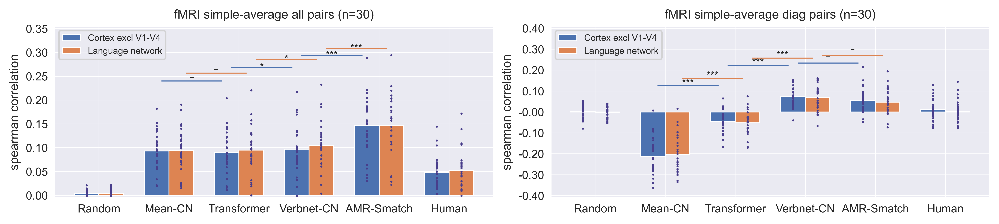


group-average
all Glasser-cortex_novis-stable-0.07-norm
 mean/transformer: diff=-0.009, t=-2.259, p=0.01564
 transformer/hybrid diff: diff=0.017, t=2.946, p=0.00308
 hybrid/graph: diff=0.072, t=8.182, p=0.00000
all LanROI-all-stable-0.07-norm
 mean/transformer: diff=0.000, t=0.072, p=0.47174
 transformer/hybrid diff: diff=0.019, t=2.974, p=0.00288
 hybrid/graph: diff=0.062, t=5.212, p=0.00001
diag Glasser-cortex_novis-stable-0.07-norm
 mean/transformer: diff=0.281, t=24.565, p=0.00000
 transformer/hybrid diff: diff=0.207, t=9.851, p=0.00000
 hybrid/graph: diff=-0.066, t=-4.269, p=0.00009
diag LanROI-all-stable-0.07-norm
 mean/transformer: diff=0.275, t=23.064, p=0.00000
 transformer/hybrid diff: diff=0.227, t=9.688, p=0.00000
 hybrid/graph: diff=-0.069, t=-3.070, p=0.00226


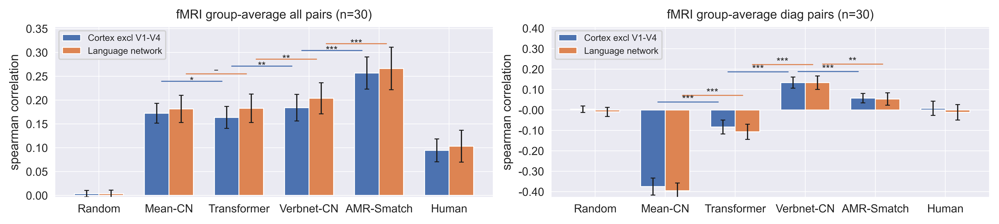

In [53]:
## Plot barplot for averaged correlation of similarities

# Select which data to plot
av_type = 'mean' # mean, tstat
voxel_set = 'standard' # standard, extended, stability, lanROIs, cortexROIs
stability_level = '0.07' # 0.04, 0.07, 0.10
show_dots = True # show individual datapoints as dots; if false show error bars instead
control_vars = vp.get_control_vars(controls_type, model_sims_storage)

# Print details
print('Including',len(included_subjects),'participants')
print('Control variables:',controls_type)
print('Stability:',stability_level)
print('Timing:',timing)
print('Similarity type:',similarity_type)

# Specify locations of y-axis ticks
if timing=='end':
    y_axes = [[(-0.005,0.305),(-0.205,0.205)],[(-0.005,0.305),(-0.41,0.21)]]
    y_ticks = [[np.arange(0.0,0.35,0.05),np.arange(-0.40,0.30,0.05)],[np.arange(0,0.35,0.05),np.arange(-0.40,0.40,0.05)]]
elif timing=='mid':
    y_axes = [[(-0.005,0.355),(-0.41,0.41)],[(-0.005,0.355),(-0.43,0.41)]]
    y_ticks = [[np.arange(0.0,0.45,0.05),np.arange(-0.50,0.50,0.10)],[np.arange(0,0.45,0.05),np.arange(-0.50,0.50,0.10)]]

# Load location of horizonal p-value signifier bars
with open("Data-analysis/Graph_params.json", "r") as file:
    hbar_params = json.load(file)
hbar_height = hbar_params[timing]['controls_'+str(controls_type)]['hbar_height']  # height of bars above axis
hbar_gap = hbar_params[timing]['controls_'+str(controls_type)]['hbar_gap']  # gap between horizontal bars
blue_adjust = hbar_params[timing]['controls_'+str(controls_type)]['blue_adjust']  # adjustments to individual blue bars
green_adjust = hbar_params[timing]['controls_'+str(controls_type)]['green_adjust']  # adjustments to individual green bars

# Set additional graph params
sns.set(font_scale=0.8, style="darkgrid", rc={"grid.linewidth": 0.5})
errorbar_parms = {'elinewidth': 0.9, 'capthick': 0.7}
lwidth = 0.7 # line width
height_gap = 0.5


# Set legend parameters
legend_location = 'upper left'
legend_size = 7
if subset_name=='llama': # needs thinner graph
    legend_location = 'upper right'
if subset_name=='fullset': # bigger legend
    legend_size = 8.5

# Initialise storage for p-values (* p<0.05/3, ** p<0.01/3, *** p<0.001/3, **** p<0.0001/3)
p_value_storage = {}

# Loop over methods of averaging over participants
for mainplot,method in enumerate(['simple-average','group-average']):
    
    # Create plot and define properties
    fig = plt.figure(figsize=(fig_width,fig_height), dpi=600)

    print('\n'+method)
    
    # Initialise storage
    size=7
    p_values_0 = {subset:np.zeros(size,dtype=object) for subset in pair_subsets} # these store the 'randm to mean-CN' comparison
    p_values_a = {subset:np.zeros(size,dtype=object) for subset in pair_subsets} # these store the 'mean-CN to transformers' comparison
    p_values_b = {subset:np.zeros(size,dtype=object) for subset in pair_subsets} # these store the 'transformers to CN-CN' comparison
    p_values_c = {subset:np.zeros(size,dtype=object) for subset in pair_subsets} # these store the 'transformers to CN-CN' comparison
    corr_means = {subset:np.zeros(size,dtype=object) for subset in pair_subsets}
    corr_stderrs = {subset:np.zeros(size,dtype=object) for subset in pair_subsets}
    corr_alldata = {subset:np.zeros(size,dtype=object) for subset in pair_subsets}
   
    # Loop over sentence pair subsets to be plotted
    for subplot,subset in enumerate(pair_subsets):
        subplot_index = subplot
        if subplot in [0,1]:
            subplot = subplot
        else:
            subplot = subplot-2
        sim_subset = similarity_subsets[subset]

        # Loop over voxel sets to be plotted
        for vox_idx,voxels in enumerate(voxel_set_dict[voxel_set]):

            if method=='simple-average':
                # compute means and standard deviations
                corr_alldata[subset][vox_idx] = [neuro_pcorrs_listsubs[included_model][av_type+'_'+subset][voxels] for included_model in included_models] # store data
                corr_means[subset][vox_idx] = np.mean(corr_alldata[subset][vox_idx],axis=1)
                corr_stdev = np.std(corr_alldata[subset][vox_idx],axis=1)
                corr_stderrs[subset][vox_idx] = stats.t.ppf(1-0.025, len(included_subjects))*(corr_stdev/np.sqrt(len(included_subjects)))
                print(subset,voxels)

                # get p-values for random-mean difference
                p_values_0[subset][vox_idx] = stats.ttest_rel(corr_alldata[subset][vox_idx][0], corr_alldata[subset][vox_idx][1]).pvalue
                
                # get p-values for mean-transformer difference
                t_test_results = stats.ttest_rel(corr_alldata[subset][vox_idx][2], corr_alldata[subset][vox_idx][1])
                p_values_a[subset][vox_idx] = t_test_results.pvalue
                mean_diff = np.mean(np.array(corr_alldata[subset][vox_idx][2])-np.array(corr_alldata[subset][vox_idx][1]))
                print(' mean/transformer: diff={:.3f}, t={:.3f}, p={:.5f}'.format(mean_diff,t_test_results[0],t_test_results[1]))
                
                # get p-values for transformer-hybrid difference
                t_test_results = stats.ttest_rel(corr_alldata[subset][vox_idx][3], corr_alldata[subset][vox_idx][2])
                p_values_b[subset][vox_idx] = t_test_results.pvalue
                mean_diff = np.mean(np.array(corr_alldata[subset][vox_idx][3])-np.array(corr_alldata[subset][vox_idx][2]))
                print(' transformer/hybrid: diff={:.3f}, t={:.3f}, p={:.5f}'.format(mean_diff,t_test_results[0],t_test_results[1]))
                
                # get p-values for transformer-hybrid difference
                t_test_results = stats.ttest_rel(corr_alldata[subset][vox_idx][4], corr_alldata[subset][vox_idx][3])
                p_values_c[subset][vox_idx] = t_test_results.pvalue
                mean_diff = np.mean(np.array(corr_alldata[subset][vox_idx][4])-np.array(corr_alldata[subset][vox_idx][3]))
                print(' hybrid/graph: diff={:.3f}, t={:.3f}, p={:.5f}'.format(mean_diff,t_test_results[0],t_test_results[1]))

            elif method=='group-average':
                # compute means and standard deviations
                corr_alldata[subset][vox_idx] = [neuro_pcorrs_listboots[included_model][av_type+'_'+subset][voxels] for included_model in included_models] # store data
                if voxels=='Glasser-primary_visual-stable-0.07-norm' and controls_type==3:
                    adjust_factor = 0.0005 # adjust visual control bars to make them invisible on graph as partial corr doesn't work for perfect multicollinearity
                else:
                    adjust_factor = 1
                corr_means[subset][vox_idx] = [adjust_factor*neuro_pcorrs_allsubjs['mean'][av_type+'_'+subset][voxels][included_model] for included_model in included_models]
                conf_int = [np.percentile(neuro_pcorrs_listboots[included_model][av_type+'_'+subset][voxels],[2.5,97.5]) for included_model in included_models]
                corr_stderrs[subset][vox_idx] = np.ptp(conf_int,axis=1)/2
                print(subset,voxels)
                
                # bootstrapping for random-mean difference
                diff_data = np.array(corr_alldata[subset][vox_idx][1])-np.array(corr_alldata[subset][vox_idx][0])
                t_stat = np.mean(diff_data)/np.std(diff_data)
                abs_pvalue = 1-stats.t.cdf(t_stat, len(included_subjects))
                p_values_0[subset][vox_idx] = min(abs_pvalue, 1-abs_pvalue) # display correct p-value

                # bootstrapping for mean-transformer difference
                diff_data = np.array(corr_alldata[subset][vox_idx][2])-np.array(corr_alldata[subset][vox_idx][1])
                t_stat = np.mean(diff_data)/np.std(diff_data)
                abs_pvalue = 1-stats.t.cdf(t_stat, len(included_subjects))
                p_values_a[subset][vox_idx] = min(abs_pvalue, 1-abs_pvalue)
                print(' mean/transformer: diff={:.3f}, t={:.3f}, p={:.5f}'.format(np.mean(diff_data),t_stat,p_values_a[subset][vox_idx]))

                # bootstrapping for transformer-hybrid difference
                diff_data = np.array(corr_alldata[subset][vox_idx][3])-np.array(corr_alldata[subset][vox_idx][2])
                t_stat = np.mean(diff_data)/np.std(diff_data)
                abs_pvalue = 1-stats.t.cdf(t_stat, len(included_subjects))
                p_values_b[subset][vox_idx] = min(abs_pvalue, 1-abs_pvalue)
                print(' transformer/hybrid diff: diff={:.3f}, t={:.3f}, p={:.5f}'.format(np.mean(diff_data),t_stat,p_values_b[subset][vox_idx]))
                
                # bootstrapping for hybrid-smatch difference
                diff_data = np.array(corr_alldata[subset][vox_idx][4])-np.array(corr_alldata[subset][vox_idx][3])
                t_stat = np.mean(diff_data)/np.std(diff_data)
                abs_pvalue = 1-stats.t.cdf(t_stat, len(included_subjects))
                p_values_c[subset][vox_idx] = min(abs_pvalue, 1-abs_pvalue)
                print(' hybrid/graph: diff={:.3f}, t={:.3f}, p={:.5f}'.format(np.mean(diff_data),t_stat,p_values_c[subset][vox_idx]))

        # Create subplot
        fig_axis = fig.add_subplot(int(str(22)+str(subplot_index+1)))
        bar_x_locs = np.arange(len(included_models))
        if voxel_set=='standard':
            bar_width = 0.35
            dot_size = 0.4
            errorbar_cap = bar_width*5
            fig.subplots_adjust(wspace=width_space, hspace=height_gap)
            if show_dots and method=='simple-average':
                fig_axis.bar(x=bar_x_locs-1*bar_width/2, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, label='Cortex excl V1-V4')
                fig_axis.bar(x=bar_x_locs+1*bar_width/2, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, label='Language network')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-1*bar_width/2], corr_alldata[subset][0], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+1*bar_width/2], corr_alldata[subset][1], c='darkslateblue', s=dot_size)
            else:
                fig_axis.bar(x=bar_x_locs-1*bar_width/2, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][0], error_kw=errorbar_parms, capsize=errorbar_cap, label='Cortex excl V1-V4')
                fig_axis.bar(x=bar_x_locs+1*bar_width/2, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][1], error_kw=errorbar_parms, capsize=errorbar_cap, label='Language network')
            plt.legend(loc=legend_location, prop={'size': legend_size})
        elif voxel_set=='extended':
            bar_width = 0.30
            errorbar_cap = bar_width*5
            fig.subplots_adjust(wspace=width_space, hspace=height_gap)
            if show_dots and method=='simple-average':
                fig_axis.bar(x=bar_x_locs-1*bar_width, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, label='Cortex excl V1-V4')
                fig_axis.bar(x=bar_x_locs-0*bar_width, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, label='LanExtend')
                fig_axis.bar(x=bar_x_locs+1*bar_width, height=corr_means[subset][2], width=bar_width, linewidth=lwidth, label='LanROI')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-1*bar_width], corr_alldata[subset][0], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-0*bar_width], corr_alldata[subset][1], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+1*bar_width], corr_alldata[subset][2], c='darkslateblue', s=dot_size)
            else:
                fig_axis.bar(x=bar_x_locs-1*bar_width, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][0], error_kw=errorbar_parms, capsize=errorbar_cap, label='Cortex excl V1-V4')
                fig_axis.bar(x=bar_x_locs-0*bar_width, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][1], error_kw=errorbar_parms, capsize=errorbar_cap, label='LanExtend')
                fig_axis.bar(x=bar_x_locs+1*bar_width, height=corr_means[subset][2], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][2], error_kw=errorbar_parms, capsize=errorbar_cap, label='LanROI')
            plt.legend(loc=legend_location, prop={'size': legend_size})
        elif voxel_set=='stability':
            bar_width = 0.20
            dot_size = 0.4
            errorbar_cap = bar_width*5
            fig.subplots_adjust(wspace=width_space, hspace=height_gap)
            if show_dots and method=='simple-average':
                fig_axis.bar(x=bar_x_locs-3*bar_width/2, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, label='all voxels')
                fig_axis.bar(x=bar_x_locs-1*bar_width/2, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, label='stability>0.04')
                fig_axis.bar(x=bar_x_locs+1*bar_width/2, height=corr_means[subset][2], width=bar_width, linewidth=lwidth, label='stability>0.07')
                fig_axis.bar(x=bar_x_locs+3*bar_width/2, height=corr_means[subset][3], width=bar_width, linewidth=lwidth, label='stability>0.10')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-3*bar_width/2], corr_alldata[subset][0], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-1*bar_width/2], corr_alldata[subset][1], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+1*bar_width/2], corr_alldata[subset][2], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+3*bar_width/2], corr_alldata[subset][3], c='darkslateblue', s=dot_size)
            else:
                fig_axis.bar(x=bar_x_locs-3*bar_width/2, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][0], error_kw=errorbar_parms, capsize=errorbar_cap, label='all voxels')
                fig_axis.bar(x=bar_x_locs-1*bar_width/2, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][1], error_kw=errorbar_parms, capsize=errorbar_cap, label='stability>0.04')
                fig_axis.bar(x=bar_x_locs+1*bar_width/2, height=corr_means[subset][2], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][2], error_kw=errorbar_parms, capsize=errorbar_cap, label='stability>0.07')
                fig_axis.bar(x=bar_x_locs+3*bar_width/2, height=corr_means[subset][3], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][3], error_kw=errorbar_parms, capsize=errorbar_cap, label='stability>0.10')
            plt.legend(loc=legend_location, prop={'size': legend_size})
        elif voxel_set=='lanROIs':
            bar_width = 0.15
            dot_size = 0.2
            errorbar_cap = bar_width*5
            fig.subplots_adjust(wspace=width_space, hspace=height_gap)
            if show_dots and method=='simple-average':
                fig_axis.bar(x=bar_x_locs-5*bar_width/2, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Anterior Temporal')
                fig_axis.bar(x=bar_x_locs-3*bar_width/2, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Posterior Temporal')
                fig_axis.bar(x=bar_x_locs-1*bar_width/2, height=corr_means[subset][2], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Angular Gyrus')
                fig_axis.bar(x=bar_x_locs+1*bar_width/2, height=corr_means[subset][3], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Medial Frontal Gyrus')
                fig_axis.bar(x=bar_x_locs+3*bar_width/2, height=corr_means[subset][4], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Inferior Frontal Gyrus')
                fig_axis.bar(x=bar_x_locs+5*bar_width/2, height=corr_means[subset][5], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Inferior Frontal Gyrus Orbital')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-5*bar_width/2], corr_alldata[subset][0], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-3*bar_width/2], corr_alldata[subset][1], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-1*bar_width/2], corr_alldata[subset][2], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+1*bar_width/2], corr_alldata[subset][3], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+3*bar_width/2], corr_alldata[subset][4], c='darkslateblue', s=dot_size)
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+5*bar_width/2], corr_alldata[subset][5], c='darkslateblue', s=dot_size)
            else:
                fig_axis.bar(x=bar_x_locs-5*bar_width/2, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][0], error_kw=errorbar_parms, capsize=errorbar_cap, label='Anterior Temporal')
                fig_axis.bar(x=bar_x_locs-3*bar_width/2, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][1], error_kw=errorbar_parms, capsize=errorbar_cap, label='Posterior Temporal')
                fig_axis.bar(x=bar_x_locs-1*bar_width/2, height=corr_means[subset][2], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][2], error_kw=errorbar_parms, capsize=errorbar_cap, label='Angular Gyrus')
                fig_axis.bar(x=bar_x_locs+1*bar_width/2, height=corr_means[subset][3], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][3], error_kw=errorbar_parms, capsize=errorbar_cap, label='Medial Frontal Gyrus')
                fig_axis.bar(x=bar_x_locs+3*bar_width/2, height=corr_means[subset][4], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][4], error_kw=errorbar_parms, capsize=errorbar_cap, label='Inferior Frontal Gyrus')
                fig_axis.bar(x=bar_x_locs+5*bar_width/2, height=corr_means[subset][5], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][5], error_kw=errorbar_parms, capsize=errorbar_cap, label='Inferior Frontal Gyrus Orbital')
            if method=='simple-average' and subset=='all': # add legend
                plt.legend(loc=legend_location, prop={'size': legend_size})
        elif voxel_set=='cortexROIs':
            bar_width = 0.12
            dot_size = 1.6
            errorbar_cap = bar_width*5
            fig.subplots_adjust(wspace=width_space, hspace=height_gap)
            if show_dots and method=='simple-average':
                fig_axis.bar(x=bar_x_locs-3*bar_width, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Dorsomedial PFC')
                fig_axis.bar(x=bar_x_locs-2*bar_width, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Dorsolateral PFC')
                fig_axis.bar(x=bar_x_locs-1*bar_width, height=corr_means[subset][2], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Posterior cingulate')
                fig_axis.bar(x=bar_x_locs-0*bar_width, height=corr_means[subset][3], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Precuneus')
                fig_axis.bar(x=bar_x_locs+1*bar_width, height=corr_means[subset][4], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Somatosensory cortex')
                fig_axis.bar(x=bar_x_locs+2*bar_width, height=corr_means[subset][5], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Visual cortex')
                fig_axis.bar(x=bar_x_locs+3*bar_width, height=corr_means[subset][6], width=bar_width, linewidth=lwidth, capsize=errorbar_cap, label='Language network')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-3*bar_width], corr_alldata[subset][0], c='darkslateblue', s=dot_size, edgecolors='none')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-2*bar_width], corr_alldata[subset][1], c='darkslateblue', s=dot_size, edgecolors='none')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-1*bar_width], corr_alldata[subset][2], c='darkslateblue', s=dot_size, edgecolors='none')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs-0*bar_width], corr_alldata[subset][3], c='darkslateblue', s=dot_size, edgecolors='none')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+1*bar_width], corr_alldata[subset][4], c='darkslateblue', s=dot_size, edgecolors='none')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+2*bar_width], corr_alldata[subset][5], c='darkslateblue', s=dot_size, edgecolors='none')
                fig_axis.scatter([np.ones(len(included_subjects)) * bar_loc for bar_loc in bar_x_locs+3*bar_width], corr_alldata[subset][6], c='darkslateblue', s=dot_size, edgecolors='none')
            else:
                fig_axis.bar(x=bar_x_locs-3*bar_width, height=corr_means[subset][0], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][0], error_kw=errorbar_parms, capsize=errorbar_cap, label='Dorsomedial PFC')
                fig_axis.bar(x=bar_x_locs-2*bar_width, height=corr_means[subset][1], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][1], error_kw=errorbar_parms, capsize=errorbar_cap, label='Dorsolateral PFC')
                fig_axis.bar(x=bar_x_locs-1*bar_width, height=corr_means[subset][2], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][2], error_kw=errorbar_parms, capsize=errorbar_cap, label='Posterior cingulate')
                fig_axis.bar(x=bar_x_locs-0*bar_width, height=corr_means[subset][3], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][3], error_kw=errorbar_parms, capsize=errorbar_cap, label='Precuneus')
                fig_axis.bar(x=bar_x_locs+1*bar_width, height=corr_means[subset][4], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][4], error_kw=errorbar_parms, capsize=errorbar_cap, label='Somatosensory cortex')
                fig_axis.bar(x=bar_x_locs+2*bar_width, height=corr_means[subset][5], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][5], error_kw=errorbar_parms, capsize=errorbar_cap, label='Visual cortex')
                fig_axis.bar(x=bar_x_locs+3*bar_width, height=corr_means[subset][6], width=bar_width, linewidth=lwidth, yerr=corr_stderrs[subset][6], error_kw=errorbar_parms, capsize=errorbar_cap, label='Language network')
            if method=='simple-average' and subset=='all': # add legend
                plt.legend(loc=legend_location, prop={'size': legend_size})
        if len(included_models) <= 6 and len(voxel_set_dict[voxel_set]) < 3: # only include horizonal p-value lines if we're plotting the smaller subset of models
            # plot the blue lines
            base_height = np.array(corr_means[subset][0])+hbar_height[mainplot][subplot]
            vp.barplot_annotate_brackets(1, 2, p_values_a[subset][0], bar_x_locs-bar_width/2, base_height+blue_adjust[mainplot][subplot][0], colour='#4c72b0', ymax=y_axes[mainplot][subplot][1], multi_test=3, fs=8, width=0.8)
            vp.barplot_annotate_brackets(2, 3, p_values_b[subset][0], bar_x_locs-bar_width/2, base_height+blue_adjust[mainplot][subplot][1], colour='#4c72b0', ymax=y_axes[mainplot][subplot][1], multi_test=3, fs=8, width=0.8)
            vp.barplot_annotate_brackets(3, 4, p_values_c[subset][0], bar_x_locs-bar_width/2, base_height+blue_adjust[mainplot][subplot][2], colour='#4c72b0', ymax=y_axes[mainplot][subplot][1], multi_test=3, fs=8, width=0.8)
            # plot the green lines
            base_height = np.array(corr_means[subset][1])+hbar_gap[mainplot][subplot]
            vp.barplot_annotate_brackets(1, 2, p_values_a[subset][1], bar_x_locs+bar_width/2, base_height+hbar_height[mainplot][subplot]+green_adjust[mainplot][subplot][0], colour='#dd8452', ymax=y_axes[mainplot][subplot][1], multi_test=3, fs=8, width=0.8)
            vp.barplot_annotate_brackets(2, 3, p_values_b[subset][1], bar_x_locs+bar_width/2, base_height+hbar_height[mainplot][subplot]+green_adjust[mainplot][subplot][1], colour='#dd8452', ymax=y_axes[mainplot][subplot][1], multi_test=3, fs=8, width=0.8)
            vp.barplot_annotate_brackets(3, 4, p_values_c[subset][1], bar_x_locs+bar_width/2, base_height+hbar_height[mainplot][subplot]+green_adjust[mainplot][subplot][2], colour='#dd8452', ymax=y_axes[mainplot][subplot][1], multi_test=3, fs=8, width=0.8)
        
        # Add labels
        plt.title('fMRI '+method+' '+subset+' pairs (n='+str(len(included_subjects))+')')
        
        # Specify axis labels
        fig_axis.set_ylabel(corr_method+' correlation')
        fig_axis.set_xticks(np.arange(len(included_models)), model_names)
        fig_axis.tick_params(axis='both',pad=-1) # set distance between ticks and tick labels
        fig_axis.set_yticks(y_ticks[mainplot][subplot]) 
        fig_axis.set_ylim(y_axes[mainplot][subplot])

        fig_axis.yaxis.set_major_formatter(FormatStrFormatter('%.2f')) # always show two decimal places
        
        # needs some adjustments to fit all models in
        if subset_name in ['fullset','hybrid']: 
            fig_axis.tick_params(axis='x', labelrotation=35)
            fig_axis.set_xlim(-1, len(included_models))

    # Store p-values
    p_value_storage[method] = (p_values_a,p_values_b,p_values_c)
    
    # Save figure
    figure_name = 'Figures\\Fodor2024-'+timing+'_control-'+str(controls_type)+'_subs-'+str(len(included_subjects))+'_models-'+subset_name+'_voxels-'+voxel_set+'_type-'+method+'_corr-'+corr_method+'_sims-'+similarity_type+'.png'
    plt.savefig(figure_name, bbox_inches='tight')
    plt.show()

### Table of all results

In [41]:
## Prepare results for printing

# Subject and models to show results
bootstrap = True
pair_set = 'all' #diag, all

# Print initial lines
print('Bootstrapping:',bootstrap)
print('Correlation type:',corr_method)
print('Control variables:',controls_type)
print('Type:',pair_set,'with',corr_method,'correlation')

# Loop over all smooth types, all model names, and all voxel sets
# Note: partical_corr function ignores control variables when they are perfectly correlated with the dependent variable, hence the high correlations shown below for 'sent_min' and 'length_diff'
data_store = {parm:[] for parm in other_parms} # initialise empty dict
for parms in other_parms:
    for model in included_models:
        new_row = []
        for voxel_set in voxel_sets:
            if bootstrap: # show data for group-averaged mean bootstrapped over subjects
                corr_mean = neuro_pcorrs_allsubjs['mean'][parms][voxel_set][model]
                conf_int = np.percentile(neuro_pcorrs_listboots[model][parms][voxel_set],[2.5,97.5])
                new_row.append(corr_mean)
            else: # show data averaged over individual subjects
                new_row.append(neuro_pcorrs_listsubs[model][parms][voxel_set])
        data_store[parms].append(new_row)
data_store = {parm:np.array(data_store[parm]) for parm in other_parms}
print('Shape:',data_store[parms].shape)

Bootstrapping: True
Correlation type: spearman
Control variables: 1
Type: all with spearman correlation
Shape: (12, 32)


In [42]:
## Table displaying all results

# Apply the function to wrap the column headers
data_store_pd = pd.DataFrame(data_store['mean_'+pair_set], index=included_models, columns=voxel_sets)
data_selected_pd = data_store_pd.loc[:, np.array(voxel_set_dict['cortexROIs'])]

# Display styled pandas df
df_styled = data_selected_pd.style.format("{:.4f}").set_properties(**{'width': '100px'})
df_styled

,Glasser-dorsomedial_PFC-stable-0.07-norm,Glasser-dorsolateral_PFC-stable-0.07-norm,Glasser-posterior_cingulate-stable-0.07-norm,Glasser-precuneus-stable-0.07-norm,Glasser-primary_sensory-stable-0.07-norm,Glasser-primary_visual-stable-0.07-norm,LanROI-all-stable-0.07-norm
parse-GPT4_embed-conceptnet_weights-equal_struct-low_verbnet,0.2681,0.2540,0.2142,0.2823,0.1011,0.2258,0.2969
parse-GPT4_embed-conceptnet_weights-equal_struct-none_verbnet,0.1005,0.0988,0.0986,0.1567,0.0171,0.0599,0.1171
parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet,0.1877,0.1875,0.2252,0.2512,0.0626,0.1114,0.2037
parse-GPT4_embed-conceptnet_weights-fixed_struct-none_verbnet,0.0635,0.0569,0.0901,0.1284,-0.0092,0.0049,0.0631
parse-GPT4_embed-conceptnet_weights-STS3k_struct-low_verbnet,0.1862,0.1753,0.1894,0.2313,0.0538,0.1242,0.2002
parse-GPT4_embed-conceptnet_weights-STS3k_struct-none_verbnet,0.0548,0.0494,0.0793,0.1197,-0.0160,0.0062,0.0591
parse-GPT4_embed-defsent_mean_weights-equal_struct-low_verbnet,0.2959,0.2711,0.2408,0.2928,0.1270,0.2462,0.3104
parse-GPT4_embed-defsent_mean_weights-equal_struct-none_verbnet,0.1708,0.1499,0.1620,0.1925,0.0787,0.1145,0.1660
parse-GPT4_embed-defsent_mean_weights-fixed_struct-low_verbnet,0.2352,0.2236,0.2647,0.2740,0.0995,0.1529,0.2365
parse-GPT4_embed-defsent_mean_weights-fixed_struct-none_verbnet,0.1276,0.1055,0.1562,0.1687,0.0510,0.0510,0.1044


### Additional plots

In [43]:
## Select what to plot
subject = 'mean'
parms = 'mean_all'
stability_level = '0.07'
voxel_set = 'cortexROIs'

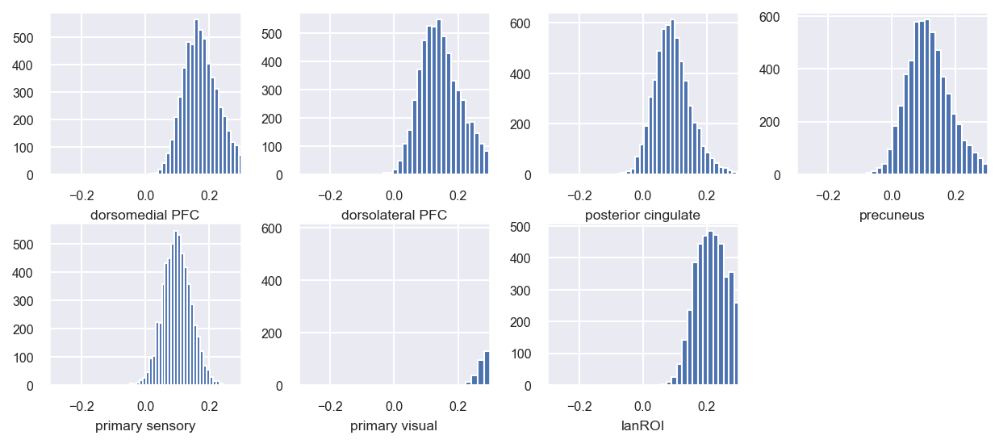

In [44]:
## Print histogram of neuro similarities

# Specify voxel sets to plot
voxel_sets_for_plot = voxel_set_dict[voxel_set]
voxel_sets_names = ['dorsomedial PFC', 'dorsolateral PFC', 'posterior cingulate','precuneus', 'primary sensory', 'primary visual', 'lanROI']

# Define plot
fig = plt.figure(figsize=(10,4), facecolor='white', dpi=150)
fig.subplots_adjust(wspace=0.3, hspace=0.3)
sns.set(font_scale=0.7)

# Generate subplots
for subplot in np.arange(len(voxel_sets_for_plot)):
    plot_num = int(str(24)+str(subplot+1))
    fig_axis = fig.add_subplot(plot_num)
    fig_axis.hist(neuro_sims_storage[subject][av_type][voxel_sets_for_plot[subplot]], bins=30)
    fig_axis.set(xlabel=voxel_sets_names[subplot])
    fig_axis.set_xlim(-0.3,0.3)
# plt.savefig('Data\\'+dataset_name+'-GLMSbetas_sub-'+str(subject)+'_similarities.png', bbox_inches='tight')
plt.show()

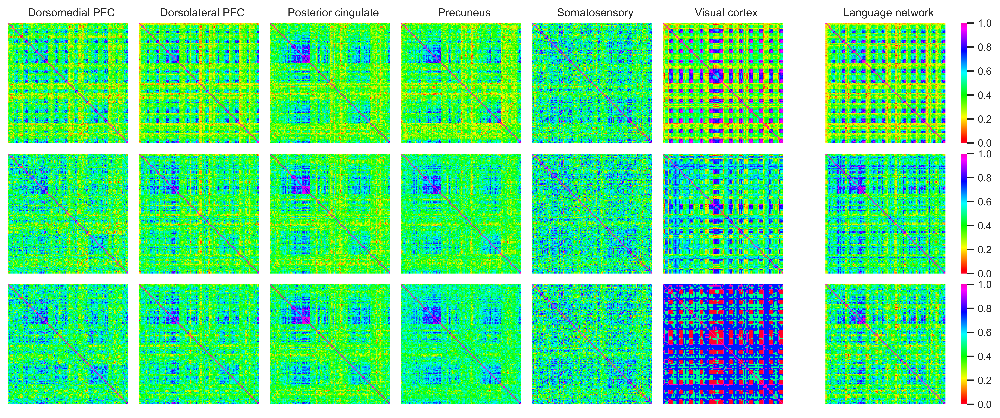

In [45]:
## Plot RSA matrices after regressing out control variables

# Choose what to plot
control_var_sets = [1,2,3]
normalise_sims = 1
group_norm = 0 # normalise sims across the whole set of voxel subsets
voxel_sets_for_plot = voxel_set_dict[voxel_set]
voxel_sets_names = ['Dorsomedial PFC', 'Dorsolateral PFC', 'Posterior cingulate','Precuneus', 'Somatosensory','Visual cortex','Language network']

# Storage for all resids
combined_sims_resids_dict = {}
combined_names = []

# Loop over all sets of control variables to compute and store resids
for graph_control in control_var_sets:
    
    # Choose controls to use
    control_vars = vp.get_control_vars(graph_control, model_sims_storage)

    # Regress out control variables from neuro sims
    neuro_sims_resids = {voxels:[] for voxels in voxel_sets_for_plot} # create storage dict
    for sub_id in included_subjects:
        neuro_sims_resid, _ = vp.regress_out_controls(neuro_sims_storage[subject][av_type], control_vars)
        [neuro_sims_resids[voxels].append(neuro_sims_resid[voxels]) for voxels in voxel_sets_for_plot]
    neuro_sims_resids_mean = {voxels:np.mean(neuro_sims_resids[voxels],axis=0) for voxels in voxel_sets_for_plot} # average over subjects
    
    # Store resids in dictionary
    for idx,voxels in enumerate(voxel_sets_for_plot):
        combined_sims_resids_dict[voxels+'_'+str(graph_control)] = neuro_sims_resids_mean[voxels]
        combined_names.append(voxel_sets_names[idx]) #+'_'+str(graph_control))


# Normalisation here adjusts the scale for plotting; doesn't affect correlations
if normalise_sims == 1:
    percentile_vis_cutoff = 0
    if subject=='mean':
        neuro_sims_storage_norml = vp.normalise_similarities(combined_sims_resids_dict, percentile_vis_cutoff, group_norm)
    else:
        neuro_sims_storage_norml = vp.normalise_similarities(neuro_sims_storage[subject][av_type], percentile_vis_cutoff, group_norm)
    min_sim = 0
    max_sim = 1
else:
    neuro_sims_storage_norml = combined_sims_resids_dict
    min_sim =-0.2
    max_sim = 0.3
    
# Define plot
fig = plt.figure(figsize=(17,4.05*len(control_var_sets)), dpi=680)
fig.subplots_adjust(wspace=-0.57, hspace=0.09)
sns.set(font_scale=0.8)

# Generate subplots
corr_matrices = []
for idx,voxels in enumerate(combined_sims_resids_dict.keys()):
    plot_num = (2*len(control_var_sets),len(voxel_sets_for_plot),idx+1)
    corr_matrix = vp.mask_based_utri2mat(neuro_sims_storage_norml[voxels][sent_pair_ids_all], 108)
    corr_matrices.append(corr_matrix)
    if (idx+1)%len(voxel_sets_for_plot)==0:
        show_colorbar=True
    else:
        show_colorbar=False
    if idx<len(voxel_sets_for_plot):
        vp.add_heatmap_subplot(fig, plot_num, corr_matrix, '', '', combined_names[idx], colorbar=show_colorbar, min=min_sim, max=max_sim)
    else:
        vp.add_heatmap_subplot(fig, plot_num, corr_matrix, '', '', '', colorbar=show_colorbar, min=min_sim, max=max_sim)
    # np.savetxt('Data\\'+dataset_name+'-GLMSbetas_sub-'+str(subject)+'_RSA-'+voxels+'.txt', corr_matrices[0], fmt='%.4f')

# Save results
figure_name = 'Figures\\Fodor2024-'+timing+'_control-'+str('all')+'_subs-'+str(len(included_subjects))+'_sims-'+similarity_type+'_RSAs.png'
plt.savefig(figure_name, bbox_inches='tight')
plt.show()

### Scatterplots

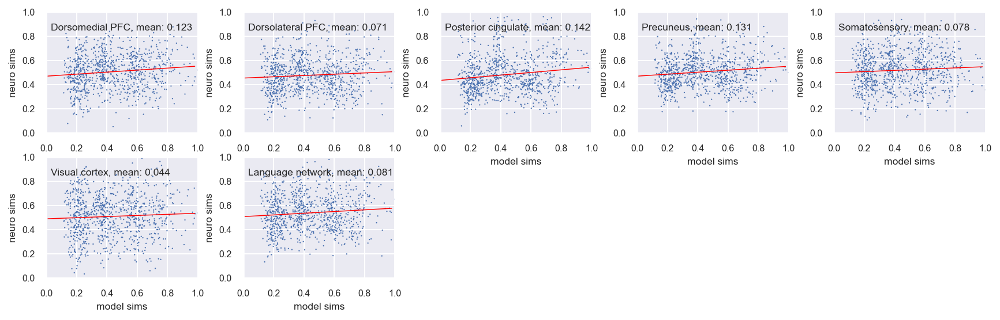

In [46]:
## Plot scatterplots with different voxel sets

# Select what to plot
send_pairs_to_plot = sent_pair_ids_diag  # subsets: sent_pair_ids_all, sent_pair_ids_diag
model_to_plot = 'parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet'

# Choose controls to use
graph_control=2
control_vars = vp.get_control_vars(graph_control, model_sims_storage)

# Normalise similarities
model_sims_resid, _ = vp.regress_out_controls(model_sims_storage, control_vars)
model_sims_storage_norml = vp.normalise_similarities(model_sims_resid, 0)
neuro_sims_resid, _ = vp.regress_out_controls(neuro_sims_storage[subject]['mean'], control_vars)
neuro_sims_storage_norml = vp.normalise_similarities(neuro_sims_resid, 0)

# Generate figure
fig = plt.figure(figsize=(14,4), facecolor='white', dpi=150)
fig.subplots_adjust(wspace=0.3, hspace=0.2)
sns.set(font_scale=0.7) # set font size for labels

# Loop over voxel sets and generate subplots
for i,voxels in enumerate(voxel_sets_for_plot):
    xs = model_sims_storage_norml[model_to_plot][send_pairs_to_plot]
    ys = np.array(neuro_sims_storage_norml[voxels])[send_pairs_to_plot]
    plot_num = (2,5,i+1)
    colours = 'b' # just use a default colour
    vp.add_scatterplot_subplot(fig, xs, ys, colours, plot_num, subject, voxel_sets_names[i], x_min=0, y_min=0, y_max=1, size=1.2)
plt.show()

Included models: ['conceptnet_mean_random_norml_cosine', 'conceptnet_mean_norml_cosine', 'conceptnet_mult_mod_norml_cosine', 'conceptnet_conv_mod_norml_cosine', 'glove6b_norml_cosine', 'infersent_norml_cosine', 'ernie_12_norml_cosine', 'llama3_32_norml_cosine', 'amrbart_12_norml_cosine', 'universal_norml_cosine', 'defsent_cls_norml_cosine', 'sentbert_mpnet_norml_cosine', 'openai_norml_cosine', 'S3BERT_global', 'benepar_subtree', 'CFG_subtree', 'AMR_hybrid', 'AMR_smatch', 'AMR_WLK', 'parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet', 'GPT4_rated', 'Prolific_rated']
Results for control=3 and 5778 sent pairs
conceptnet_mean_random_norml_cosine spearman: 0.009
conceptnet_mean_random_norml_cosine pearson: 0.028
conceptnet_mean_norml_cosine spearman: -0.364
conceptnet_mean_norml_cosine pearson: -0.351
conceptnet_mult_mod_norml_cosine spearman: -0.360
conceptnet_mult_mod_norml_cosine pearson: -0.360
conceptnet_conv_mod_norml_cosine spearman: -0.071
conceptnet_conv_mod_norml_cosine

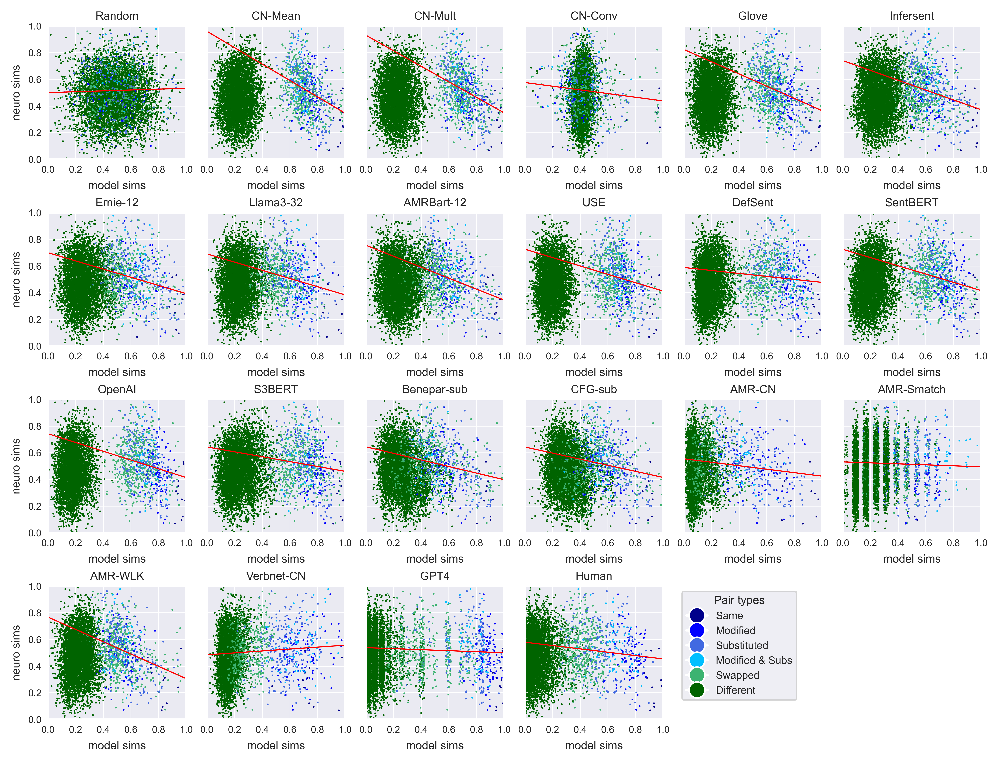

In [47]:
## Plot scatterplots versus models

# Select what to plot and parameters
model_set = 'fullset'
if model_set=='rsmb':
    models_shortnames = ['conceptnet_mean_norml','openai','conceptnet_weights-fixed_struct-low_verbnet','AMR_smatch']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Mean-CN', 'OpenAI', 'Verbnet-CN', 'AMR-Smatch']
    num_per_row = 4
    fig_width = 7
elif model_set=='fullset':
    models_shortnames = ['random', 'conceptnet_mean_norml', 'conceptnet_mult_mod', 'conceptnet_conv_mod', 'glove', 'infersent', 
                         'ernie_12', 'llama3_32', 'amrbart_12', 'universal', 'defsent_cls', 'sentbert_mpnet', 'openai', 
                         'S3BERT_global', 'benepar_subtree', 'CFG_subtree', 'AMR', 'conceptnet_weights-fixed_struct-low_verbnet', 'rated']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Random', 'CN-Mean', 'CN-Mult', 'CN-Conv', 'Glove', 'Infersent',
                   'Ernie-12', 'Llama3-32', 'AMRBart-12', 'USE', 'DefSent', 'SentBERT', 'OpenAI', 
                   'S3BERT', 'Benepar-sub', 'CFG-sub', 'AMR-CN', 'AMR-Smatch', 'AMR-WLK', 'Verbnet-CN', 'GPT4', 'Human']
    num_per_row = 6
    fig_width = 10.5
sent_pairs_to_plot = np.intersect1d(sent_pair_ids_all,sent_pair_ids_all) # subsets: sent_pair_ids_all, sent_pair_ids_diag
sent_pairs_for_line = np.intersect1d(sent_pair_ids_all,sent_pair_ids_diag)
stability_level = '0.07'
voxel_set = 'LanROI-all-stable-'+stability_level+'-norm'

# Choose controls to use
graph_control = 3
control_vars = vp.get_control_vars(graph_control, model_sims_storage)

# Print description
print('Results for control='+str(graph_control)+' and '+str(len(sent_pairs_to_plot))+' sent pairs')

# Prepare colors for type categories
type_colors = ['red', 'darkblue', 'blue','royalblue', 'deepskyblue', 'mediumseagreen', 'darkgreen']
type_labels = ['', 'Same', 'Modified', 'Substituted', 'Modified & Subs', 'Swapped', 'Different']

# Normalise data for plotting
model_sims_storage_norml = vp.normalise_similarities(model_sims_storage, 0)
neuro_sims_resid, _ = vp.regress_out_controls(neuro_sims_storage['mean']['mean'], control_vars)
neuro_sims_storage_norml = vp.normalise_similarities(neuro_sims_resid, 0.1)

# Produce figure
fig = plt.figure(figsize=(fig_width,4.2*len(included_models)), facecolor='white', dpi=700)
fig.subplots_adjust(wspace=0.15, hspace=0.4)
dot_size = 1.2
sns.set(font_scale=0.6, rc={"grid.linewidth": 0.5}) # set font size for labels
for i,model in enumerate(included_models):

    # Add a single scatterplot subplot
    plot_num = (2*len(included_models),num_per_row,i+1)
    fig_axis = fig.add_subplot(*plot_num)
    fig_axis.set_title(model_names[i], pad=4)
    fig_axis.set_xlim(0,1)
    fig_axis.set_xticks(np.arange(0,1.01,0.2))
    fig_axis.set_ylim(0,1)
    fig_axis.tick_params(axis='both', which='major', pad=-2, labelsize=6)
    if i%num_per_row==0: # for the every fourth only
        fig_axis.set(ylabel='neuro sims', xlabel='model sims')
    else: # for all other subplots
        fig_axis.set(xlabel='model sims')
        fig_axis.set_yticklabels([])

    # Add jitters to model data
    jit_size = 0.02
    jitters = np.random.uniform(-jit_size, jit_size, len(sent_pair_ids_all))
    model_sims_norml_jittered = ((model_sims_storage_norml[model]+jitters)+jit_size)/(1+2*jit_size) # renormalise after jitter

    # Plot data
    ys = np.array(neuro_sims_storage_norml[voxel_set])[sent_pairs_to_plot].reshape(-1, 1)
    xs = model_sims_norml_jittered[sent_pairs_to_plot].reshape(-1, 1)
    colours = [type_colors[v] for v in sentpair_types_list[sent_pairs_to_plot]]
    fig_axis.scatter(xs, ys, c=colours, marker='o', s=dot_size, edgecolor='none')
    
    # Add regression line and diagonal line
    xs_raw = model_sims_storage_norml[model][sent_pairs_for_line].reshape(-1, 1)
    ys_raw =  np.array(neuro_sims_storage_norml[voxel_set])[sent_pairs_for_line].reshape(-1, 1)
    OLS_reg = LinearRegression(fit_intercept=True).fit(xs_raw, ys_raw)
    reg_scorr = spearmanr(ys_raw.reshape(-1), xs_raw.reshape(-1))[0]
    reg_pcorr = pearsonr(ys_raw.reshape(-1), xs_raw.reshape(-1))[0]
    plot_xs = np.arange(0,1,0.001).reshape(-1, 1)
    pred_ys = OLS_reg.predict(plot_xs)
    plt.plot(plot_xs, pred_ys, color='red', linewidth=0.7) # add reg line

    # Print correlations
    # plt.text(0.03, 0.90, 'Corr: {:.3f}'.format(reg_scorr))
    print(model+' spearman: {:.3f}'.format(spearmanr(ys_raw.reshape(-1), xs_raw.reshape(-1))[0]))
    print(model+' pearson: {:.3f}'.format(pearsonr(ys_raw.reshape(-1), xs_raw.reshape(-1))[0]))

# Add legend
legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label=label, markerfacecolor=color, markersize=10)
                for color, label in zip(type_colors[1:], type_labels[1:])]
plt.legend(handles=legend_elements, title='Pair types', bbox_to_anchor=(1.1,1))

# Save and display results
plt.savefig('Figures\\Fodor2024-'+timing+'_control-'+str(graph_control)+'_subs-'+str(len(included_subjects))+'_models-'+model_set+'_sims-'+similarity_type+'_scatterplots.png', bbox_inches='tight')
plt.show()

### Subject-wise results

Average corr all: 0.104
Average corr noneng: 0.108
Average corr eng: 0.103


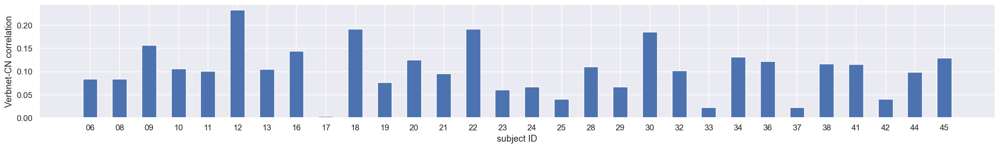

TtestResult(statistic=np.float64(0.27402457186554674), pvalue=np.float64(0.7866728859117634), df=np.float64(21.569247159724064))


In [48]:
## Show specified correlations for each subject

# Specify parameters
parms = 'mean_all'
voxel_set = 'LanROI-all-stable-'+stability_level+'-norm'
model_name = 'parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet'
model_label = 'Verbnet-CN'

# Prepare subject data
subject_corrs = []
noneng_subject_corrs = []
eng_subject_corrs = []
noneng_subjects = ['06','07','14','16','21','23','31','34','36','38','39','40','43'] # participant ID from non-English majority countries
eng_subjects = [idx for idx in all_subjects if idx not in noneng_subjects]
for sbj_id in all_subjects:
    if sbj_id in included_subjects:
        subject_corrs.append(neuro_pcorrs_allsubjs[sbj_id][parms][voxel_set][model_name])
for sbj_id in noneng_subjects:
    if sbj_id in included_subjects:
        noneng_subject_corrs.append(neuro_pcorrs_allsubjs[sbj_id][parms][voxel_set][model_name])
for sbj_id in eng_subjects:
    if sbj_id in included_subjects:
        eng_subject_corrs.append(neuro_pcorrs_allsubjs[sbj_id][parms][voxel_set][model_name])
print('Average corr all: {:.3}'.format(np.mean(subject_corrs)))
print('Average corr noneng: {:.3}'.format(np.mean(noneng_subject_corrs)))
print('Average corr eng: {:.3}'.format(np.mean(eng_subject_corrs)))
    
# Generate plot
sns.set(font_scale=1.1)
fig = plt.figure(figsize=(25,3))
plt.bar(x=np.arange(len(included_subjects)), height=subject_corrs, width=0.5, capsize=2)
plt.xticks(np.arange(len(included_subjects)), included_subjects)
plt.ylabel(model_label+' correlation')
plt.xlabel('subject ID')
plt.show()

# Perform t-test for eng and noneng participants
test_output = stats.ttest_ind(noneng_subject_corrs, eng_subject_corrs, equal_var=False)
print(test_output)

Results for control=3 and 5778 sent pairs
Corrs all: [np.float64(0.09620207935502843) np.float64(0.11113255764271207) np.float64(0.07853613726418661) np.float64(0.08400330746521661) np.float64(0.04578977997564111) np.float64(-0.023560505313100704)
 np.float64(0.13056883032264893)]


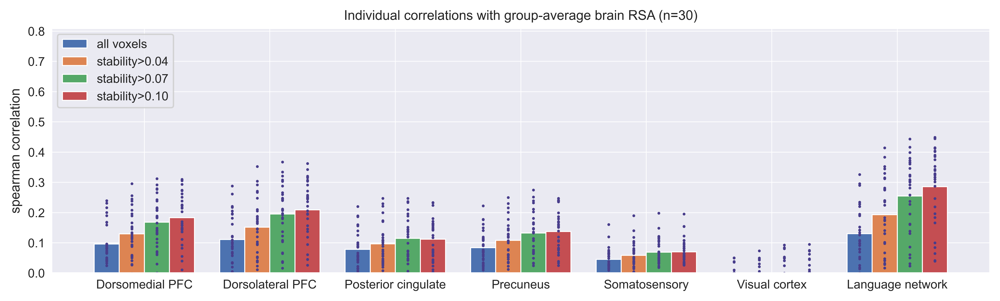

In [49]:
## Plot barplot for averaged correlation of similarities

# Select which data to plot
av_type = 'mean' # mean, tstat
plot_type = 'by_stability' #by_subset, by_stability
voxel_sets_for_plot = voxel_set_dict['cortexROIs']
voxel_sets_names = ['Dorsomedial PFC', 'Dorsolateral PFC', 'Posterior cingulate','Precuneus', 'Somatosensory','Visual cortex','Language network']
stabilities = ['','-stable-0.04','-stable-0.07','-stable-0.1']

# Choose controls to use
graph_control=3
control_vars = vp.get_control_vars(graph_control, model_sims_storage)

# Create plot and define properties
sns.set(font_scale=0.8, style="darkgrid", rc={"grid.linewidth": 0.5})
errorbar_parms = {'elinewidth': 0.9, 'capthick': 0.7}
fig = plt.figure(figsize=(3.8*len(voxel_sets_for_plot),7), dpi=600)

# Print description
print('Results for control='+str(graph_control)+' and '+str(len(sent_pairs_to_plot))+' sent pairs')

# Version where we arrange by pair subset
if plot_type == 'by_subset':

    # Set fixed params
    stability_level = '0.07'
    bar_width = 0.30
    
    # Load data
    participant_data = {key:neuro_sims_storage[key][av_type]['LanROI-all-stable-'+stability_level+'-norm'] for key in all_subjects}
    
    # Initialise storage
    corrs_all = {subset:np.zeros(len(voxel_sets_for_plot),dtype=object) for subset in pair_subsets}
    corrs_mean = {subset:np.zeros(len(voxel_sets_for_plot),dtype=object) for subset in pair_subsets}

    # Loop over subsets to be plotted
    for subplot,subset in enumerate(pair_subsets):
        sim_subset = similarity_subsets[subset]

        # Loop over voxel sets to be plotted
        for vox_idx,voxels in enumerate(voxel_sets_for_plot):
            # get correlations of all participants RSA with the group-averaged-less-one RSA
            corrs_with_mean_less_one_dict = {}
            for sbj_id in list(participant_data.keys()):
                mean_less_one = np.mean([neuro_sims_storage[sbj][av_type][voxels] for sbj in participant_data.keys() if sbj not in [sbj_id,'mean']],axis=0)
                corrs_with_mean_less_one_dict[sbj_id] = list(vp.calc_neuro_model_correlations(mean_less_one, participant_data, control_vars, [sbj_id], sim_subset, method=corr_method, shuffle=False)[2].values())[0][1]
            corrs_with_mean_list = [corrs_with_mean_less_one_dict[sbj] for sbj in included_subjects] 
            corrs_all[subset][vox_idx] = np.array(corrs_with_mean_list) # data for all participants
            corrs_mean[subset][vox_idx] = np.mean(corrs_with_mean_list) # average over participants

    # Create subplot
    fig_axis = fig.add_subplot(int(str(22)+str(subplot+1)))
    bar_x_locs = np.arange(len(corrs_all[subset]))
    fig_axis.bar(x=bar_x_locs-bar_width/2, linewidth=0.7, height=corrs_mean[pair_subsets[0]], width=bar_width, label='All sentence pairs')
    fig_axis.bar(x=bar_x_locs+bar_width/2, linewidth=0.7, height=corrs_mean[pair_subsets[1]], width=bar_width, label='Diag sentence pairs')
    for idx,_ in enumerate(voxel_sets_for_plot):
        fig_axis.scatter([np.ones(len(corrs_with_mean_list)) * bar_loc for bar_loc in bar_x_locs-bar_width/2][idx], corrs_all[pair_subsets[0]][idx], c='darkslateblue', s=1)
        fig_axis.scatter([np.ones(len(corrs_with_mean_list)) * bar_loc for bar_loc in bar_x_locs+bar_width/2][idx], corrs_all[pair_subsets[1]][idx], c='darkslateblue', s=1)
    fig_axis.set_xticks(np.arange(len(corrs_all['all'])), voxel_sets_names)

# Version where we arrange by stability threshold
elif plot_type == 'by_stability': 
    
    # Set fixed params
    subset = 'all'
    bar_width = 0.20
    sim_subset = similarity_subsets[subset]
    
    # Initialise storage
    corrs_all = {subset:np.zeros(len(voxel_sets_for_plot),dtype=object) for subset in stabilities}
    corrs_mean = {subset:np.zeros(len(voxel_sets_for_plot),dtype=object) for subset in stabilities}

    # Loop over all stability scores
    for subplot,stability in enumerate(stabilities):
        
        # Load data
        participant_data = {key:neuro_sims_storage[key][av_type]['Glasser-cortex_novis'+stability+'-norm'] for key in all_subjects}

        # Loop over voxel sets to be plotted
        for vox_idx,voxels in enumerate(voxel_sets_for_plot):
            # get correlations of all participants RSA with the group-averaged-less-one RSA
            corrs_with_mean_less_one_dict = {}
            for sbj_id in list(participant_data.keys()):
                mean_less_one = np.mean([neuro_sims_storage[sbj][av_type][voxels] for sbj in participant_data.keys() if sbj not in [sbj_id,'mean']],axis=0)
                corrs_with_mean_less_one_dict[sbj_id] = vp.calc_neuro_model_correlations(mean_less_one, participant_data, control_vars, [sbj_id], sim_subset, method=corr_method, shuffle=False)[1][sbj_id]
            corrs_with_mean_list = [corrs_with_mean_less_one_dict[sbj] for sbj in included_subjects] 
            corrs_mean[stability][vox_idx] = np.mean(corrs_with_mean_list) # average over participants
            corrs_all[stability][vox_idx] = np.array(corrs_with_mean_list) # data for all participants
            
    # Create subplot
    fig_axis = fig.add_subplot(int(str(22)+str(subplot+1)))
    bar_x_locs = np.arange(len(corrs_all[stability]))
    fig_axis.bar(x=bar_x_locs-(3/2)*bar_width, linewidth=0.7, height=corrs_mean[stabilities[0]], width=bar_width, label='all voxels')
    fig_axis.bar(x=bar_x_locs-(1/2)*bar_width, linewidth=0.7, height=corrs_mean[stabilities[1]], width=bar_width, label='stability>0.04')
    fig_axis.bar(x=bar_x_locs+(1/2)*bar_width, linewidth=0.7, height=corrs_mean[stabilities[2]], width=bar_width, label='stability>0.07')
    fig_axis.bar(x=bar_x_locs+(3/2)*bar_width, linewidth=0.7, height=corrs_mean[stabilities[3]], width=bar_width, label='stability>0.10')
    for idx,_ in enumerate(voxel_sets_for_plot):
        fig_axis.scatter([np.ones(len(corrs_with_mean_list)) * bar_loc for bar_loc in bar_x_locs-(3/2)*bar_width][idx], corrs_all[stabilities[0]][idx], c='darkslateblue', s=1)
        fig_axis.scatter([np.ones(len(corrs_with_mean_list)) * bar_loc for bar_loc in bar_x_locs-(1/2)*bar_width][idx], corrs_all[stabilities[1]][idx], c='darkslateblue', s=1)
        fig_axis.scatter([np.ones(len(corrs_with_mean_list)) * bar_loc for bar_loc in bar_x_locs+(1/2)*bar_width][idx], corrs_all[stabilities[2]][idx], c='darkslateblue', s=1)
        fig_axis.scatter([np.ones(len(corrs_with_mean_list)) * bar_loc for bar_loc in bar_x_locs+(3/2)*bar_width][idx], corrs_all[stabilities[3]][idx], c='darkslateblue', s=1)
    fig_axis.set_xticks(np.arange(len(corrs_all[stability])), voxel_sets_names)
        
# Add labels
plt.title('Individual correlations with group-average brain RSA (n='+str(len(included_subjects))+')')
plt.legend(loc='upper left')
print('Corrs all:',corrs_mean[''])

# Specify axis labels
fig_axis.set_ylabel(corr_method+' correlation')
fig_axis.set_yticks(np.arange(0,0.81,0.1))
fig_axis.set_ylim(0,0.81)
fig_axis.tick_params(axis='both',pad=-1.3) # set distance between ticks and tick labels

# Save figure
figure_name = 'Figures\\Fodor2024-'+timing+'_control-'+str(graph_control)+'_subs-'+str(len(included_subjects))+'_group_corr.png'
plt.savefig(figure_name, bbox_inches='tight')
plt.show()

In [50]:
## Compute pairwise correlations between subjects

# compute correlations for each participant
np.seterr(divide='ignore', invalid='ignore') # ignore errors resulting from correlation of each subject with themselves
participant_data = {key:neuro_sims_storage[key][av_type][voxel_set] for key in included_subjects}
subjectwise_corrs_all = {}
for sbj_id in included_subjects:
    subjectwise_corrs = vp.calc_neuro_model_correlations(neuro_sims_storage[sbj_id][av_type][voxel_set], participant_data, control_vars, list(participant_data.keys()), sim_subset, method=corr_method, shuffle=False)[0]
    subjectwise_corrs_all[sbj_id] = subjectwise_corrs

# pairwise average between participants
sbj_pairs_all = list(itertools.combinations(included_subjects, 2))
pairwise_corrs = []
for sbj_pair in sbj_pairs_all:
    pairwise_corrs.append(subjectwise_corrs_all[sbj_pair[0]][sbj_pair[1]])
print(voxel_set+' average pairwise correlation: {:.3f}'.format(np.mean(pairwise_corrs)))

LanROI-all-stable-0.07-norm average pairwise correlation: 0.222


Included models: ['conceptnet_mean_norml_cosine', 'openai_norml_cosine', 'parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet', 'AMR_smatch']
Subjects: 38
Model: AMR_smatch
Pairs: diag
Stability: 0.07
Control variables: 1
Timing: mid


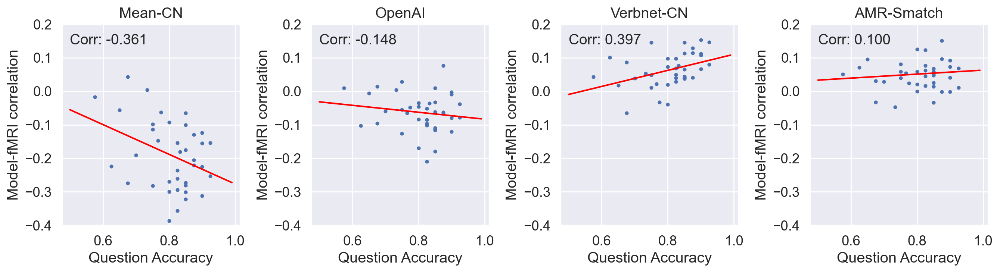

In [51]:
## Data quality plot

# Select data to use
accuracy_threshold = 0.4
movement_threshold = 10
subjects_for_plot = [sbj_id for sbj_id in subject_data_dict.keys() if subject_data_dict[sbj_id][0] >= accuracy_threshold and subject_data_dict[sbj_id][1] <= movement_threshold]
models_shortnames = ['conceptnet_mean_norml','openai','conceptnet_weights-fixed_struct-low_verbnet','AMR_smatch']
models_to_plot = vp.get_included_models(model_sims_storage, models_shortnames)
model_names = ['Mean-CN', 'OpenAI', 'Verbnet-CN', 'AMR-Smatch']
pairs_subset = 'diag' # all, diag
voxel_set = 'Glasser-cortex_novis-stable-'+stability_level+'-norm'
# voxel_set = 'LanROI-all-stable-'+stability_level+'-norm'

# Create plot
sns.set(font_scale=1.2)
fig = plt.figure(figsize=(4*len(models_to_plot),3.5), facecolor='white', dpi=200)
fig.subplots_adjust(wspace=0.4, hspace=0.2)
    
for i,model_name in enumerate(models_to_plot):
    
    # Get plot number
    plot_num = (1,len(models_to_plot),i+1)
    
    # Storage arrays
    correlations = []
    partial_correlations = []
    accuracies = []
    motions = []

    # Loop over all subjects to extract correlation and accuracy data
    for sbj_id in subjects_for_plot:
        corr = neuro_corrs_allsubjs[sbj_id]['mean_'+pairs_subset][voxel_set][model_name]
        pcorr = neuro_pcorrs_allsubjs[sbj_id]['mean_'+pairs_subset][voxel_set][model_name]
        acc = subject_data_dict[sbj_id][0]
        motion = subject_data_dict[sbj_id][1]
        correlations.append(corr)
        partial_correlations.append(pcorr)
        accuracies.append(acc)
        motions.append(motion)

    # Fit regression model
    Xs = np.array(accuracies)
    ys = np.array(correlations)
    fit_type = 'linear'
    def fit_func(Xs, a, b):
        if fit_type=='exp':
            out = a * np.exp(-b * Xs) # exponential fit
        elif fit_type=='linear':
            out = a * Xs + b # linear fit
        return out
    params, cov = curve_fit(fit_func, Xs, ys, p0=[0,-6])
    y_pred = fit_func(Xs, *params) # get predicted y-valus
    r_square = r2_score(ys, y_pred) # get r-square

    # Add model points and line to plot
    x_points = np.arange(0.5,1.0,step=0.01)
    fig_axis = fig.add_subplot(*plot_num)
    plt.plot(x_points, fit_func(x_points,*params), color='red', linewidth=1.5) # add reg line
    plt.scatter(accuracies, correlations, s=7)

    # Add labels
    plt.title(model_names[i])
    plt.ylabel('Model-fMRI correlation')
    plt.ylim(-0.4,0.2)
    plt.xlabel('Question Accuracy')
    plt.text(0.5, 0.14, 'Corr: {:.3f}'.format(np.corrcoef(Xs,ys)[0][1]), fontsize=14)

# Print information
print('Subjects:',len(subjects_for_plot))
print('Model:',model_name)
print('Pairs:',pairs_subset)
print('Stability:',stability_level)
print('Control variables:',controls_type)
print('Timing:',timing)

# Save figure
figure_name = 'Figures\\Fodor2024-'+timing+'_control-'+str(controls_type)+'_voxels-'+voxel_set[0:6]+'_corr-'+corr_method+'_sims-'+similarity_type+'_question_corr.png'
plt.savefig(figure_name, bbox_inches='tight')
plt.show()